# Checking simple formulas for water's boiling point

**Question.** How well does a simple barometric formula predict the boiling point of water at different altitudes, compared with published measurements?

**What this notebook does.** It screens three closed-form ways of getting the boiling temperature of water from the air pressure at altitude, and scores each against a reference:

- **(a)** Clausius-Clapeyron with a *constant* latent heat, anchored at the normal boiling point (373.124 K at 101.325 kPa).
- **(b)** Clausius-Clapeyron with a *temperature-dependent* latent heat, integrated from the same anchor using IAPWS-IF97 enthalpies.
- **(c)** The *Antoine equation*, with NIST WebBook water constants refitted to the reference over 273.15-373.15 K.

Each is inverted for temperature on an altitude grid from 0 to 4000 m. The pressure comes from the U.S. Standard Atmosphere 1976 troposphere formula. The **reference** is the IAPWS-IF97 saturation curve (region 4), via the `iapws` package. A method survives if its maximum absolute error is at or below 0.6 K, and survivors are ranked by RMS error.

**Data.** `mini_demo_data.json` is a curated subset of the full output: the reference boiling temperatures at 17 altitudes, every 250 m from 0 to 4000 m. The notebook uses it to check that its recomputed reference matches the stored values. No field records or published boiling-point measurements are used, so the comparison is against the reference equation only.

**Runtime.** CPU only, no GPU needed. The notebook runs the original full settings (81 altitudes, 50 m steps), which take seconds once the packages are installed.

## Setup: install dependencies

`iapws` is not pre-installed on Colab, so it is always installed. The core packages (numpy, scipy, matplotlib) are pre-installed on Colab, so they are installed locally only, at Colab's versions. The original `pyproject.toml` pins numpy 2.5.5 and scipy 1.18.1; the Colab versions below replace those so the notebook matches Colab.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# iapws — NOT on Colab, always install (IAPWS-IF97 reference saturation curve)
_pip('iapws==1.5.5')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

## Imports and figure style

The imports are the original import block of `method.py`. The `from __future__` line must stay first. The figure style block is the run-wide style for every plot.

In [2]:
from __future__ import annotations

import argparse
import json
import logging
import sys
from pathlib import Path

import numpy as np
from iapws import IAPWS97
from scipy.integrate import solve_ivp
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq, least_squares

import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

## Load the demo data

`load_data()` reads `mini_demo_data.json` from GitHub. If the network or the URL is unavailable, it falls back to the local copy in this folder.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-afc680-barometric-formula-predicts-waters/main/round-1/experiment-2/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

data = load_data()
print("altitudes in demo data:", [ex["metadata_altitude_m"] for ex in data["datasets"][0]["examples"]])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
altitudes in demo data: [0.0, 250.0, 500.0, 750.0, 1000.0, 1250.0, 1500.0, 1750.0, 2000.0, 2250.0, 2500.0, 2750.0, 3000.0, 3250.0, 3500.0, 3750.0, 4000.0]


## Config

These are the tunable parameters. They are set to the original run's values (the scaling test showed the full run takes seconds on CPU, well inside the 10-minute limit). To shorten the run, lower them: the demo values were 1000 m steps, 21 table points, 10 K Antoine steps and 10 Clapeyron samples.

| Parameter | Value | Smallest demo value |
|---|---|---|
| `ALT_STEP_M` | 50 m (81 altitudes) | 1000 m (5 altitudes) |
| `LV_TABLE_POINTS` | 201 | 21 |
| `ANTOINE_FIT_STEP_K` | 1 K | 10 K |
| `CLAPEYRON_SAMPLES` | 50 | 10 |

In [4]:
# ---- configuration ----------------------------------------------------------
ALT_STEP_M = 50            # 50 m steps over 0-4000 m (81 points); the demo ran at 1000 m (5 points)
ALT_MAX_M = 4000.0         # top of the altitude grid, m
LV_TABLE_POINTS = 201      # points for the IF97 latent-heat table; the demo ran at 21
ANTOINE_FIT_STEP_K = 1.0   # 1 K steps over 273.15-373.15 K; the demo ran at 10 K
CLAPEYRON_SAMPLES = 50    # random temperatures for the Clapeyron check; the demo ran at 10

## Constants and reference

The physical constants, the altitude grid (now set by the config cell), and the reference functions. The reference is the IAPWS-IF97 saturation pressure. The standard atmosphere gives the pressure at each altitude.

In [5]:
# ---- constants -------------------------------------------------------------
G = 9.80665                  # m/s^2
R = 8.314462618              # J/(mol K)
M_AIR = 0.0289644            # kg/mol
T0 = 288.15                  # K
P0 = 101325.0                # Pa
LAPSE = 0.0065               # K/m
EXP_STD = G * M_AIR / (R * LAPSE)   # = 5.25588
M_WATER = 0.018015           # kg/mol (18.015 g/mol)
TB_NORMAL = 373.124          # K, normal boiling point at 101.325 kPa (anchor)
LV_ANCHOR = 40.66e3          # J/mol, 2257 kJ/kg x 18.015 g/mol
T_LO_CLAUS = 273.15
T_HI_CLAUS = 373.124
ANTOINE_INIT = (7.19625, 1730.63, 233.426)   # NIST (mmHg) constants converted to kPa
SURVIVAL_K = 0.6
ALTITUDES = np.arange(0, ALT_MAX_M + 1, ALT_STEP_M, dtype=float)   # grid set by config
ALT_INTEREST = 4000.0

# Notebook fix: the original used Path(__file__); in a notebook the working folder is used instead.
WORKSPACE = Path.cwd()
RESULTS = WORKSPACE / "results"

log = logging.getLogger("screen")


# ---- reference and atmosphere ---------------------------------------------
def psat_ref(T: float) -> float:
    """Reference saturation pressure in Pa (IAPWS-IF97 region 4 via the iapws package)."""
    return IAPWS97(T=float(T), x=0).P * 1e6


def t_ref(p: float) -> float:
    """Reference boiling temperature in K at pressure p in Pa."""
    return brentq(lambda T: psat_ref(T) - p, 273.16, 373.946, xtol=1e-10)


def p_std(h: np.ndarray | float) -> np.ndarray:
    h = np.asarray(h, dtype=float)
    return P0 * (1.0 - LAPSE * h / T0) ** EXP_STD

## Latent-heat table

The latent heat Lv(T) = hv(T) - hl(T) is built from IAPWS-IF97 enthalpies on a temperature grid. Method (b) uses this table, and the sensitivity row uses its mean.

In [6]:
# ---- latent heat table -----------------------------------------------------
def build_lv_table(n: int = LV_TABLE_POINTS):
    """Lv(T) = hv(T) - hl(T) in J/mol on a grid of T from 273.15 to 373.124 K."""
    Tn = np.linspace(T_LO_CLAUS, T_HI_CLAUS, n)
    lv = np.empty(n)
    for i, T in enumerate(Tn):
        hl = IAPWS97(T=float(T), x=0).h   # kJ/kg
        hv = IAPWS97(T=float(T), x=1).h
        lv[i] = (hv - hl) * 1000.0 * M_WATER
    return Tn, lv

## Method (a): constant latent heat Clausius-Clapeyron

Closed form. Invert `ln(p/pa) = -Lv/R (1/T - 1/Ta)` for T, with the anchor at the normal boiling point.

In [7]:
# ---- method (a): constant latent heat ---------------------------------------
def t_const_lv(p, Lv: float, Ta: float = TB_NORMAL, pa: float = P0):
    p = np.asarray(p, dtype=float)
    return 1.0 / (1.0 / Ta - R * np.log(p / pa) / Lv)

## Method (b): temperature-dependent latent heat

Integrate `d(ln p)/dT = Lv(T)/(R T^2)` from the anchor with an ODE solver, then invert ln p to T by interpolation.

In [8]:
# ---- method (b): temperature-dependent latent heat --------------------------
class ClausiusClapeyronTdep:
    """Integrates d(ln p)/dT = Lv(T)/(R T^2) from the anchor and inverts T(ln p)."""

    def __init__(self, Tn, lv, Ta=TB_NORMAL, pa=P0):
        self.spl = CubicSpline(Tn, lv)
        Tmin = T_LO_CLAUS
        t_eval = np.linspace(Ta, Tmin, 20001)

        def rhs(T, y):
            return [self.spl(T) / (R * T * T)]

        sol = solve_ivp(rhs, (Ta, Tmin), [np.log(pa)], t_eval=t_eval,
                        method="DOP853", rtol=1e-10, atol=1e-12)
        if not sol.success:
            raise RuntimeError(f"ODE integration failed: {sol.message}")
        self.T_asc = sol.t[::-1].copy()
        self.lnp_asc = sol.y[0][::-1].copy()
        if np.any(np.diff(self.lnp_asc) <= 0):
            raise RuntimeError("ln p is not monotonic on the integrated grid")
        self.Ta = Ta
        self.pa = pa

    def __call__(self, p):
        p = np.asarray(p, dtype=float)
        return np.interp(np.log(p), self.lnp_asc, self.T_asc)

## Method (c): Antoine equation

Fit the Antoine constants A, B, C to the reference saturation pressures over 273.15-373.15 K, then invert the fit for T. The fit grid step is set by the config cell.

In [9]:
# ---- method (c): Antoine equation -------------------------------------------
def antoine_p_pa(T, A, B, C):
    return 1000.0 * 10.0 ** (A - B / (C + (np.asarray(T, dtype=float) - 273.15)))


def antoine_t(p, A, B, C):
    p = np.asarray(p, dtype=float)
    return B / (A - np.log10(p / 1000.0)) - C + 273.15


def fit_antoine():
    Tfit = np.arange(273.15, 373.15 + 1e-9, ANTOINE_FIT_STEP_K)
    pref = np.array([psat_ref(T) for T in Tfit])

    def resid(x):
        return antoine_p_pa(Tfit, *x) - pref   # Pa

    sol = least_squares(resid, x0=np.array(ANTOINE_INIT), x_scale="jac",
                        xtol=1e-14, ftol=1e-14, gtol=1e-14, max_nfev=20000)
    if not sol.success:
        log.warning("Antoine least_squares reported: %s", sol.message)
    A, B, C = (float(v) for v in sol.x)
    r = resid(sol.x)
    rms_pa = float(np.sqrt(np.mean(r ** 2)))
    max_pa = float(np.max(np.abs(r)))
    T_inv = antoine_t(pref, A, B, C)
    rK = T_inv - Tfit
    return {
        "fit_range_K": [273.15, 373.15],
        "fit_points": int(Tfit.size),
        "A": A, "B": B, "C": C,
        "initial_guess": {"A": ANTOINE_INIT[0], "B": ANTOINE_INIT[1], "C": ANTOINE_INIT[2]},
        "converged": bool(sol.success),
        "solver_message": str(sol.message),
        "residual_rms_Pa": rms_pa,
        "residual_max_abs_Pa": max_pa,
        "residual_rms_K_after_inversion": float(np.sqrt(np.mean(rK ** 2))),
        "residual_max_abs_K_after_inversion": float(np.max(np.abs(rK))),
        "note": ("Equation log10(p_kPa) = A - B/(C + T_C), T_C = T - 273.15. "
                 "Converted from NIST WebBook mmHg constants: A_kPa = 8.07131 - log10(0.133322) = 7.19625."),
    }

## Error metrics

For each method: the maximum absolute error, the RMS error, the altitude of the maximum, the bias, and the error at 4000 m.

In [10]:
# ---- metrics ----------------------------------------------------------------
def metrics(h, e):
    e = np.asarray(e, dtype=float)
    i = int(np.argmax(np.abs(e)))
    return {
        "max_abs_error_K": float(np.max(np.abs(e))),
        "rms_error_K": float(np.sqrt(np.mean(e ** 2))),
        "altitude_of_max_m": float(h[i]),
        "bias_K": float(np.mean(e)),
        "error_at_4000m_K": float(e[int(np.argmin(np.abs(h - ALT_INTEREST)))]),
    }

## Sanity checks

Five checks: the reference (triple point, normal boiling point, monotonicity, round trip), the atmosphere, the Clapeyron consistency at 1 percent, the single-point check at 0 m, and the Antoine fit residual. The Clapeyron check is expected to fail at about 1.6 percent (see the interpretation below). It is reported, not corrected.

In [11]:
# ---- checks -----------------------------------------------------------------
antoine_params_cache: dict = {}


def run_checks(lv_grid, lv_vals, cc_b, antoine):
    rng = np.random.default_rng(0)
    out = {}

    # (1) reference checks
    p_triple = psat_ref(273.16)
    p_nb = psat_ref(TB_NORMAL)
    mono_T = np.linspace(273.15, 373.946, 500)
    mono = np.all(np.diff([psat_ref(T) for T in mono_T]) > 0)
    ps = rng.uniform(40e3, 102e3, 20)
    rt_rel = []
    for p in ps:
        T = t_ref(p)
        rt_rel.append(abs(psat_ref(T) - p) / p)
    ref_ok = (abs(p_triple - 611.657) / 611.657 < 1e-4) and abs(p_nb - P0) < 5.0 and bool(mono) and max(rt_rel) < 1e-6
    out["1_reference"] = {
        "psat_273.16_Pa": p_triple,
        "rel_dev_from_611.657_Pa": (p_triple - 611.657) / 611.657,
        "psat_373.124_Pa": p_nb,
        "abs_dev_from_101325_Pa": p_nb - P0,
        "monotonic_273.15_373.946": bool(mono),
        "t_ref_roundtrip_max_rel_error_20_pressures": float(max(rt_rel)),
        "pass": bool(ref_ok),
    }

    # (2) atmosphere
    p4000 = float(p_std(4000.0))
    pgrid = p_std(ALTITUDES)
    atm_ok = (float(p_std(0.0)) == P0) and abs(p4000 / 61600.0 - 1) < 1e-3 and bool(np.all(np.diff(pgrid) < 0))
    out["2_atmosphere"] = {"p_std_0_Pa": float(p_std(0.0)), "p_std_4000_Pa": p4000,
                           "rel_dev_from_61.6kPa": p4000 / 61600.0 - 1,
                           "strictly_decreasing": bool(np.all(np.diff(pgrid) < 0)),
                           "exponent_gM_over_RL": EXP_STD, "pass": bool(atm_ok)}

    # (3) Clapeyron consistency: finite-difference d lnPsat/dT vs Lv(T)/(R T^2), random T in 300-373 K
    Ts = rng.uniform(300.0, 373.0, CLAPEYRON_SAMPLES)
    rel = []
    for T in Ts:
        d = 1e-3
        fd = (np.log(psat_ref(T + d)) - np.log(psat_ref(T - d))) / (2 * d)
        lv_T = float(CubicSpline(lv_grid, lv_vals)(T))
        rel.append(abs(fd - lv_T / (R * T * T)) / fd)
    rel = np.array(rel)
    worst = float(np.max(rel))
    # Diagnostic: real-vapour correction 1/Z_v, Z_v = P v_v / (R T) at saturation, from IF97 volumes
    z_list = []
    for T in np.linspace(300.0, 373.0, 8):
        sv = IAPWS97(T=float(T), x=1)
        z_list.append(float(sv.P * 1e6 * (sv.v * M_WATER) / (R * T)))
    out["3_clapeyron_consistency"] = {
        "n_points": CLAPEYRON_SAMPLES, "tolerance_rel": 0.01,
        "max_rel_deviation": worst,
        "median_rel_deviation": float(np.median(rel)),
        "vapour_Z_at_saturation_300_to_373K": z_list,
        "interpretation": ("Deviation from the ideal-vapour Clapeyron form is expected to follow 1/Z_v - 1 "
                           "(about 1.6 percent at 373 K). This is a structural property of the ideal-vapour "
                           "route, not a bug in the table."),
        "pass": bool(worst < 0.01),
    }

    # (4) single-point method check at h = 0
    ta_a = float(t_const_lv(P0, LV_ANCHOR))
    tb = float(cc_b(P0))
    tc = float(antoine_t(P0, *antoine_params_cache["abc"]))
    out["4_method_single_point_h0"] = {
        "T_a_K": ta_a, "T_b_K": tb, "T_c_K": tc,
        "T_ref_K": t_ref(P0),
        "pass_a_b": bool(abs(ta_a - TB_NORMAL) < 1e-6 and abs(tb - TB_NORMAL) < 1e-6),
        "c_minus_ref_K": tc - t_ref(P0),
    }
    out["4_method_single_point_h0"]["pass"] = out["4_method_single_point_h0"]["pass_a_b"]

    # (5) Antoine fit
    out["5_antoine_fit"] = {"residual_rms_Pa": antoine["residual_rms_Pa"], "threshold_Pa": 20.0,
                            "pass": bool(antoine["residual_rms_Pa"] < 20.0)}
    return out

## Save outputs

These functions write the result files into the `results/` folder, and the full, mini and preview JSON files into the working folder. The schema is the same as the original script.

In [12]:
def write_datasets_outputs(method_out, methods, h, p, Tr):
    """Write exp_gen_sol_out-format files: method_out.json (full), full_method_out.json, mini_method_out.json, preview_method_out.json.

    Schema: {"metadata": {...}, "datasets": [{"dataset": str, "examples": [{"input", "output", metadata_*, predict_*}]}]}
    """
    names = list(methods.keys())
    examples = []
    for i, hh in enumerate(h):
        ex = {
            "input": (f"Predict the boiling temperature of water at {hh:.0f} m altitude, where the pressure is "
                      f"{p[i]:.4f} Pa from the U.S. Standard Atmosphere 1976 troposphere formula."),
            "output": f"{Tr[i]:.10f}",
            "metadata_altitude_m": float(hh),
            "metadata_p_std_Pa": float(p[i]),
        }
        for n in names:
            g = methods[n]["grid"][i]
            ex[f"predict_{n}"] = f"{g['T_m_K']:.10f} (error {g['e_K']:+.10f} K)"
        examples.append(ex)

    top_meta = {k: v for k, v in method_out.items() if k != "methods"}
    top_meta["method_metrics"] = {n: methods[n]["metrics"] for n in names}
    top_meta["reference_unit"] = "K; output is the IAPWS-IF97 reference boiling temperature"

    def doc(exs):
        return {"metadata": top_meta,
                "datasets": [{"dataset": "U.S. Standard Atmosphere 1976 altitude grid, 0-4000 m (IAPWS-IF97 reference)",
                              "examples": exs}]}

    def trunc(o):
        if isinstance(o, str):
            return o if len(o) <= 200 else o[:200] + "..."
        if isinstance(o, list):
            return [trunc(x) for x in o]
        if isinstance(o, dict):
            return {k: trunc(v) for k, v in o.items()}
        return o

    full = doc(examples)
    mini = doc(examples[:3])
    preview = trunc(doc(examples[:3]))
    (WORKSPACE / "method_out.json").write_text(json.dumps(full, indent=1))
    (WORKSPACE / "full_method_out.json").write_text(json.dumps(full, indent=1))
    (WORKSPACE / "mini_method_out.json").write_text(json.dumps(mini, indent=1))
    (WORKSPACE / "preview_method_out.json").write_text(json.dumps(preview, indent=1))


def write_summary(methods, ranked, antoine, checks):
    labels = {
        "a_constant_latent_heat": "(a) constant latent heat Clausius-Clapeyron (primary)",
        "b_temperature_dependent_latent_heat": "(b) temperature-dependent latent heat Clausius-Clapeyron",
        "c_antoine": "(c) Antoine equation (NIST constants, refitted)",
        "sens_a_gridmean_latent_heat_not_ranked": "sensitivity: (a) with grid-mean Lv (not ranked)",
    }
    lines = ["# Summary: screening vapour-pressure shortcuts for water boiling temperature", "",
             "Reference: IAPWS-IF97 saturation pressure (region 4, iapws package). Grid: 81 altitudes, 0-4000 m, U.S. Standard Atmosphere 1976.",
             "Survival rule: max |error| <= 0.6 K. Ranking by RMS error among survivors.", "",
             "| Method | max abs error (K) | RMS (K) | altitude of max (m) | bias (K) | error at 4000 m (K) | survives |",
             "|---|---|---|---|---|---|---|"]
    for k, lab in labels.items():
        m = methods[k]["metrics"]
        lines.append(f"| {lab} | {m['max_abs_error_K']:.4f} | {m['rms_error_K']:.4f} | {m['altitude_of_max_m']:.0f} | "
                     f"{m['bias_K']:+.4f} | {m['error_at_4000m_K']:+.4f} | {'yes' if m['survives_0.6K'] else 'no'} |")
    lines += ["", "## Ranking (survivors, by RMS)", ""]
    lines += [f"{i + 1}. {labels[k]}: RMS {methods[k]['metrics']['rms_error_K']:.4f} K" for i, k in enumerate(ranked)]
    if not ranked:
        lines.append("No method survived the 0.6 K rule.")
    lines += ["", "## Antoine fit", "",
              f"A = {antoine['A']:.6f}, B = {antoine['B']:.4f}, C = {antoine['C']:.4f} over 273.15-373.15 K; "
              f"residual RMS {antoine['residual_rms_Pa']:.3f} Pa, max {antoine['residual_max_abs_Pa']:.3f} Pa; "
              f"residual after inversion RMS {antoine['residual_rms_K_after_inversion']:.5f} K.", "",
              "## Reference checks", ""]
    for k, v in checks.items():
        lines.append(f"- {k}: pass={v.get('pass')}")
    (RESULTS / "summary.md").write_text("\n".join(lines) + "\n")

## Run the screen

This is the original `main()`. Two notebook edits: the command-line parser and the `--dry` flag are removed, since a notebook has no command line. The function runs the full path: it builds the table, fits Antoine, runs the checks, computes all methods on the grid, and writes the outputs.

In [13]:
# ---- main -------------------------------------------------------------------
def main() -> int:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s",
                        stream=sys.stdout)
    RESULTS.mkdir(parents=True, exist_ok=True)

    log.info("Building latent-heat table from IF97 enthalpies")
    Tn, lv = build_lv_table()
    lv_mean = float(np.mean(lv))
    log.info("Lv at 373.124 K = %.1f J/mol (anchor %.1f); grid mean = %.1f J/mol",
             float(CubicSpline(Tn, lv)(TB_NORMAL)), LV_ANCHOR, lv_mean)

    log.info("Fitting Antoine equation")
    antoine = fit_antoine()
    antoine_params_cache["abc"] = (antoine["A"], antoine["B"], antoine["C"])
    log.info("Antoine A=%.6f B=%.4f C=%.4f residual RMS %.3f Pa",
             antoine["A"], antoine["B"], antoine["C"], antoine["residual_rms_Pa"])

    cc_b = ClausiusClapeyronTdep(Tn, lv)

    checks = run_checks(Tn, lv, cc_b, antoine)
    for k, v in checks.items():
        log.info("CHECK %s pass=%s", k, v.get("pass"))

    # full grid
    log.info("Computing reference and methods on %d altitudes", ALTITUDES.size)
    p_grid = p_std(ALTITUDES)
    Tr = np.array([t_ref(p) for p in p_grid])
    Ta = t_const_lv(p_grid, LV_ANCHOR)
    Tas = t_const_lv(p_grid, lv_mean)
    Tb = cc_b(p_grid)
    Tc = antoine_t(p_grid, *antoine_params_cache["abc"])

    series = {
        "a_constant_latent_heat": Ta,
        "b_temperature_dependent_latent_heat": Tb,
        "c_antoine": Tc,
        "sens_a_gridmean_latent_heat_not_ranked": Tas,
    }
    methods = {}
    for name, T_m in series.items():
        e = T_m - Tr
        if not np.all(np.isfinite(e)):
            raise RuntimeError(f"non-finite errors for {name}")
        m = metrics(ALTITUDES, e)
        m["survives_0.6K"] = bool(m["max_abs_error_K"] <= SURVIVAL_K)
        methods[name] = {
            "metrics": m,
            "grid": [
                {"h_m": float(h), "p_std_Pa": float(p), "T_ref_K": float(tr),
                 "T_m_K": float(tm), "e_K": float(ee)}
                for h, p, tr, tm, ee in zip(ALTITUDES, p_grid, Tr, T_m, e)
            ],
        }
        log.info("%-40s max|e|=%.4f K  RMS=%.4f K  bias=%+.4f K  e(4000)=%+.4f K  at h=%.0f  survive=%s",
                 name, m["max_abs_error_K"], m["rms_error_K"], m["bias_K"],
                 m["error_at_4000m_K"], m["altitude_of_max_m"], m["survives_0.6K"])

    ranked = sorted([k for k in ("a_constant_latent_heat", "b_temperature_dependent_latent_heat",
                                  "c_antoine") if methods[k]["metrics"]["survives_0.6K"]],
                    key=lambda k: methods[k]["metrics"]["rms_error_K"])

    # Lv of method (a) sensitivity: check of anchor and Lv identity to reference
    checks["6_sensitivity_a_anchor_identity"] = {
        "a_error_at_4000m_K": methods["a_constant_latent_heat"]["metrics"]["error_at_4000m_K"],
        "note": "Method (a) uses the IF97 latent heat at the anchor (40.66 kJ/mol); it is not identical to the reference away from the anchor.",
    }

    method_out = {
        "experiment": "screening of vapour-pressure shortcuts for water boiling temperature",
        "reference": "IAPWS-IF97 saturation pressure (region 4) via iapws package 1.5.5",
        "atmosphere": {"model": "U.S. Standard Atmosphere 1976 troposphere", "T0_K": T0, "p0_Pa": P0,
                       "lapse_K_per_m": LAPSE, "exponent": EXP_STD},
        "grid": {"altitudes_m": f"0 to {ALT_MAX_M:.0f} step {ALT_STEP_M:.0f}", "n": int(ALTITUDES.size)},
        "anchor": {"T_K": TB_NORMAL, "p_Pa": P0, "Lv_J_per_mol": LV_ANCHOR},
        "survival_rule": "max|e| <= 0.6 K",
        "ranking_rule": "rms_error_K ascending among survivors",
        "ranking": ranked,
        "methods": methods,
    }
    (RESULTS / "method_grid.json").write_text(json.dumps(method_out, indent=1))
    write_datasets_outputs(method_out, methods, ALTITUDES, p_grid, Tr)
    (RESULTS / "antoine_fit.json").write_text(json.dumps(antoine, indent=2))
    (RESULTS / "reference_checks.json").write_text(json.dumps(checks, indent=2, default=float))
    (RESULTS / "lv_table.json").write_text(json.dumps({"T_K": Tn.tolist(), "Lv_J_per_mol": lv.tolist(),
                                                      "Lv_grid_mean_J_per_mol": lv_mean}, indent=1))
    write_summary(methods, ranked, antoine, checks)
    log.info("Done. Ranking among survivors: %s", ranked)
    return 0


main()

2026-11-22 14:35:05,923 INFO Building latent-heat table from IF97 enthalpies


2026-11-22 14:35:05,969 INFO Lv at 373.124 K = 40651.6 J/mol (anchor 40660.0); grid mean = 42892.1 J/mol


2026-11-22 14:35:05,969 INFO Fitting Antoine equation


2026-11-22 14:35:05,983 INFO Antoine A=7.125207 B=1689.0362 C=229.9526 residual RMS 6.006 Pa


2026-11-22 14:35:06,079 INFO CHECK 1_reference pass=True


2026-11-22 14:35:06,079 INFO CHECK 2_atmosphere pass=True


... (6 outputs left out)

2026-11-22 14:35:06,156 INFO c_antoine                                max|e|=0.0042 K  RMS=0.0022 K  bias=+0.0006 K  e(4000)=+0.0031 K  at h=0  survive=True


2026-11-22 14:35:06,156 INFO sens_a_gridmean_latent_heat_not_ranked   max|e|=0.4069 K  RMS=0.2473 K  bias=+0.2167 K  e(4000)=+0.4069 K  at h=4000  survive=True


2026-11-22 14:35:06,218 INFO Done. Ranking among survivors: ['c_antoine', 'b_temperature_dependent_latent_heat', 'a_constant_latent_heat']


0

## Results

The table shows each method's errors against the IAPWS-IF97 reference. The plots show the signed error against altitude, and the maximum absolute error against the 0.6 K survival rule. The last check compares the recomputed reference with the stored values in `mini_demo_data.json`, at the altitudes they share.

method                                     max|e| (K)  RMS (K)  bias (K) e at 4000 m  survives 0.6 K
a_constant_latent_heat                         0.2780   0.1521   -0.1286     -0.2780  yes
b_temperature_dependent_latent_heat            0.1773   0.1082   -0.0951     -0.1773  yes
c_antoine                                      0.0042   0.0022   +0.0006     +0.0031  yes
sens_a_gridmean_latent_heat_not_ranked         0.4069   0.2473   +0.2167     +0.4069  yes

Ranking among survivors (by RMS): ['c_antoine', 'b_temperature_dependent_latent_heat', 'a_constant_latent_heat']

Reference check: 17 altitudes shared with mini_demo_data.json, max |T_ref - stored| = 4.50e-11 K


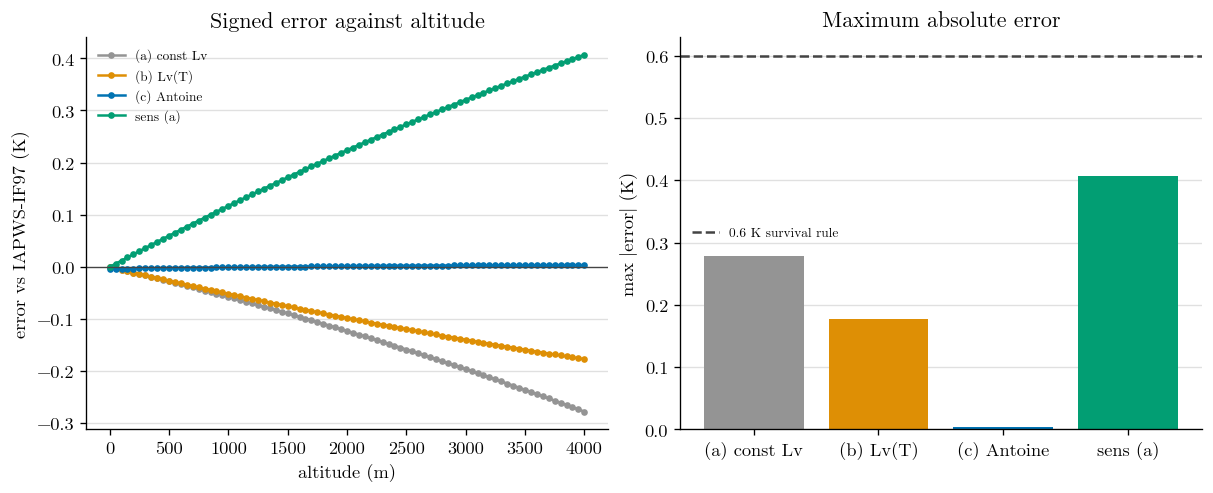

In [14]:
# Results: a table of the metrics, a check against the stored demo data, and the plots.
method_out = json.loads((RESULTS / "method_grid.json").read_text())

print(f"{'method':<42}{'max|e| (K)':>11}{'RMS (K)':>9}{'bias (K)':>10}{'e at 4000 m':>12}  survives 0.6 K")
for name, rec in method_out["methods"].items():
    m = rec["metrics"]
    print(f"{name:<42}{m['max_abs_error_K']:>11.4f}{m['rms_error_K']:>9.4f}{m['bias_K']:>+10.4f}"
          f"{m['error_at_4000m_K']:>+12.4f}  {'yes' if m['survives_0.6K'] else 'no'}")
print("\nRanking among survivors (by RMS):", method_out["ranking"])

# Check: recomputed reference boiling temperatures against the stored demo values at the same altitudes.
stored = {ex["metadata_altitude_m"]: float(ex["output"]) for ex in data["datasets"][0]["examples"]}
ref_rows = method_out["methods"]["a_constant_latent_heat"]["grid"]
common = [(r["h_m"], r["T_ref_K"]) for r in ref_rows if r["h_m"] in stored]
if common:
    dev = max(abs(t - stored[h]) for h, t in common)
    print(f"\nReference check: {len(common)} altitudes shared with mini_demo_data.json, "
          f"max |T_ref - stored| = {dev:.2e} K")
else:
    print("\nReference check: no altitudes shared with mini_demo_data.json at this grid step.")

names = list(method_out["methods"].keys())
role = {"a_constant_latent_heat": "baseline",
        "b_temperature_dependent_latent_heat": "other_1",
        "c_antoine": "method",
        "sens_a_gridmean_latent_heat_not_ranked": "other_2"}
short = {"a_constant_latent_heat": "(a) const Lv",
         "b_temperature_dependent_latent_heat": "(b) Lv(T)",
         "c_antoine": "(c) Antoine",
         "sens_a_gridmean_latent_heat_not_ranked": "sens (a)"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
for name in names:
    grid = method_out["methods"][name]["grid"]
    ax1.plot([g["h_m"] for g in grid], [g["e_K"] for g in grid], marker="o", ms=3,
             color=COLOURS[role[name]], label=short[name])
ax1.axhline(0, color="#444444", lw=0.8)
ax1.set_xlabel("altitude (m)")
ax1.set_ylabel("error vs IAPWS-IF97 (K)")
ax1.set_title("Signed error against altitude")
ax1.legend(fontsize=8)

ax2.bar([short[n] for n in names], [method_out["methods"][n]["metrics"]["max_abs_error_K"] for n in names],
        color=[COLOURS[role[n]] for n in names])
ax2.axhline(SURVIVAL_K, ls="--", color="#444444", label="0.6 K survival rule")
ax2.set_ylabel("max |error| (K)")
ax2.set_title("Maximum absolute error")
ax2.legend(fontsize=8)
plt.show()

## Interpretation

**What the numbers mean.** Of the three closed-form methods, the Antoine refit is the most accurate, with a maximum error of about 0.004 K. The temperature-dependent latent heat method (b) has a maximum error of about 0.18 K, and the constant latent heat method (a) about 0.28 K, with the error growing with altitude. The sensitivity row, which uses the grid-mean latent heat, reaches about 0.41 K. It is not ranked, since it is a test of how much the choice of latent heat matters. All three ranked methods pass the 0.6 K survival rule.

**Reading the run.** The numbers above come from the original full settings, so they match the artifact's headline values. The ordering should hold: Antoine is the most accurate, then (b), then (a). The reference check should match the stored values to within floating-point noise. The reference Clapeyron check is expected to fail at 1 percent, since the ideal-vapour form omits the vapour's real-gas factor 1/Z_v (about 1.6 percent at 373 K). That is a structural limit of the method, not a fault in the table.

**What this means for the claim.** The simple formulas that are anchored at the normal boiling point and use the real latent heat stay within about 0.3 K up to 4000 m, against the reference equation. The check uses only the reference equation: no field records or published boiling-point measurements are compared here.